In [ ]:
from google.colab import userdata
token = userdata.get("GITHUB_TOKEN")
!git clone https://{token}@github.com/sayfeldinn/t20-brain-tumor-detection.git /content/t20-brain-tumor-detection

Cloning into '/content/t20-brain-tumor-detection'...
remote: Enumerating objects: 7101, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 7101 (delta 0), reused 3 (delta 0), pack-reused 7093 (from 1)
Receiving objects: 100% (7101/7101), 148.85 MiB | 16.99 MiB/s, done.
Resolving deltas: 100% (22/22), done.
Updating files: 100% (7227/7227), done.


In [ ]:
%cd /content/t20-brain-tumor-detection
import pandas as pd
df = pd.read_csv("split_manifest.csv")
df["path"] = "/content/t20-brain-tumor-detection/" + df["path"]
print(df.groupby(["split", "label"]).size().unstack())

/content/t20-brain-tumor-detection
label  glioma  meningioma  notumor  pituitary
split                                        
test      400         400      400        400
train    1190        1190     1190       1190
val       210         210      210        210


In [ ]:
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32

import os, random
import numpy as np
import torch
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

train_df = df[df.split == "train"].reset_index(drop=True)
val_df   = df[df.split == "val"].reset_index(drop=True)
test_df  = df[df.split == "test"].reset_index(drop=True)

class MRIDataset(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame["path"].tolist()
        self.labels = [CLASSES.index(l) for l in frame["label"]]
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), self.labels[i]


train_tf = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
])

eval_tf = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
])

train_ds = MRIDataset(train_df, train_tf)
val_ds   = MRIDataset(val_df, eval_tf)
test_ds  = MRIDataset(test_df, eval_tf)

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=2)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


xb, yb = next(iter(train_loader))
print(xb.shape, xb.dtype, xb.min().item(), xb.max().item())
print(len(train_ds), len(val_ds), len(test_ds))

torch.Size([32, 3, 224, 224]) torch.float32 0.0 1.0
4760 840 1600


In [ ]:
import time, copy, os
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet50_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


def gpu_mem_mb():
    return torch.cuda.max_memory_allocated() // 1024**2 if torch.cuda.is_available() else 0
def reset_gpu_mem():
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()


class Normalized(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return self.base((x - self.mean) / self.std)

def build_resnet50_frozen():
    m = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
    for p in m.parameters():
        p.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, 4)
    return Normalized(m)

def set_train_mode(model, frozen):
    model.train()
    if frozen:
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()

@torch.no_grad()
def evaluate(model, loader, crit):
    model.eval()
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        tot += crit(out, y).item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    return tot / n, correct / n

def run_training(model, run_id, arch, strategy, lr, frozen, max_epochs=15, patience=3):
    model.to(device)
    crit = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr)

    best_val_loss, best_val_acc, best_state, bad = float("inf"), 0.0, None, 0
    epoch_times, history = [], []
    reset_gpu_mem()
    t_all = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        t0 = time.perf_counter()
        set_train_mode(model, frozen)
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward()
            opt.step()
        epoch_times.append(time.perf_counter() - t0)

        vl, va = evaluate(model, val_loader, crit)
        history.append(vl)
        print(f"{run_id} epoch {epoch:2d} | val_loss={vl:.4f} | val_acc={va:.4f} | {epoch_times[-1]:.1f}s")

        if vl < best_val_loss:
            best_val_loss, best_val_acc, bad = vl, va, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print(f"{run_id}: early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    total = time.perf_counter() - t_all

    tmp = "/content/_tmp_size.pt"
    torch.save(model.state_dict(), tmp)
    size_mb = round(os.path.getsize(tmp) / 1024**2, 2)
    os.remove(tmp)

    return {
        "framework": "pytorch", "architecture": arch, "strategy": strategy, "run_id": run_id,
        "epochs_run": len(epoch_times),
        "seconds_per_epoch": round(sum(epoch_times) / len(epoch_times), 2),
        "total_train_seconds": round(total, 2),
        "peak_gpu_memory_mb": gpu_mem_mb(),
        "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "total_params": sum(p.numel() for p in model.parameters()),
        "saved_model_size_mb": size_mb,
        "best_val_loss": round(best_val_loss, 4),
        "best_val_acc": round(best_val_acc, 4),
        "notes": f"Adam lr={lr}, batch=32, frozen backbone, BN in eval mode",
        "_history": history,
    }


model_r1 = build_resnet50_frozen()
r1 = run_training(model_r1, "R1", "ResNet50", "frozen_backbone", lr=1e-3, frozen=True)
print({k: v for k, v in r1.items() if k != "_history"})

device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 84.6MB/s]


R1 epoch  1 | val_loss=0.5077 | val_acc=0.8286 | 25.7s
R1 epoch  2 | val_loss=0.4232 | val_acc=0.8393 | 24.4s
R1 epoch  3 | val_loss=0.4204 | val_acc=0.8583 | 23.5s
R1 epoch  4 | val_loss=0.3387 | val_acc=0.8917 | 23.3s
R1 epoch  5 | val_loss=0.4456 | val_acc=0.8214 | 24.7s
R1 epoch  6 | val_loss=0.3310 | val_acc=0.8821 | 23.3s
R1 epoch  7 | val_loss=0.2922 | val_acc=0.9024 | 23.4s
R1 epoch  8 | val_loss=0.2944 | val_acc=0.8964 | 23.7s
R1 epoch  9 | val_loss=0.2926 | val_acc=0.8952 | 24.2s
R1 epoch 10 | val_loss=0.3141 | val_acc=0.8857 | 23.2s
R1: early stopping at epoch 10
{'framework': 'pytorch', 'architecture': 'ResNet50', 'strategy': 'frozen_backbone', 'run_id': 'R1', 'epochs_run': 10, 'seconds_per_epoch': 23.94, 'total_train_seconds': 278.97, 'peak_gpu_memory_mb': 569, 'trainable_params': 8196, 'total_params': 23516228, 'saved_model_size_mb': 90.01, 'best_val_loss': 0.2922, 'best_val_acc': 0.9024, 'notes': 'Adam lr=0.001, batch=32, frozen backbone, BN in eval mode'}


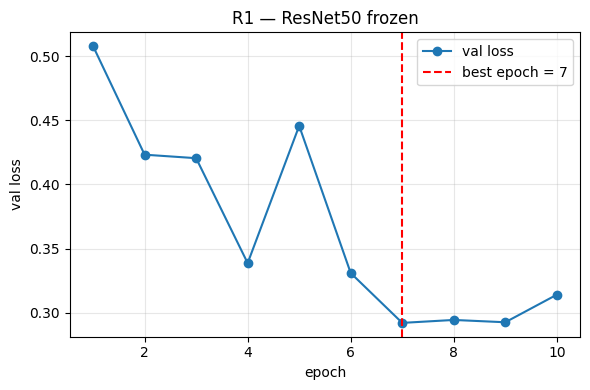

saved R1 -> /content/t20-brain-tumor-detection/results/metrics_pytorch.json
[
  {
    "framework": "pytorch",
    "architecture": "ResNet50",
    "strategy": "frozen_backbone",
    "run_id": "R1",
    "epochs_run": 10,
    "seconds_per_epoch": 23.94,
    "total_train_seconds": 278.97,
    "peak_gpu_memory_mb": 569,
    "trainable_params": 8196,
    "total_params": 23516228,
    "saved_model_size_mb": 90.01,
    "best_val_loss": 0.2922,
    "best_val_acc": 0.9024,
    "notes": "Adam lr=0.001, batch=32, frozen backbone, BN in eval mode"
  }
]


In [ ]:
import json, os
import matplotlib.pyplot as plt


hist = r1["_history"]
best_ep = hist.index(min(hist)) + 1
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(hist) + 1), hist, marker="o", label="val loss")
plt.axvline(best_ep, color="red", linestyle="--", label=f"best epoch = {best_ep}")
plt.xlabel("epoch"); plt.ylabel("val loss"); plt.title("R1 — ResNet50 frozen")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


RES_PATH = "/content/t20-brain-tumor-detection/results/metrics_pytorch.json"

def save_run(run):
    with open(RES_PATH) as f:
        data = json.load(f)
    clean = {k: v for k, v in run.items() if k != "_history"}
    data["runs"] = [r for r in data["runs"] if r["run_id"] != clean["run_id"]] + [clean]
    with open(RES_PATH, "w") as f:
        json.dump(data, f, indent=2)
    print(f"saved {clean['run_id']} -> {RES_PATH}")

save_run(r1)
print(json.dumps(json.load(open(RES_PATH))["runs"], indent=2)[:800])

R2 epoch  1 | val_loss=0.1769 | val_acc=0.9345 | 27.1s
R2 epoch  2 | val_loss=0.2061 | val_acc=0.9274 | 25.6s
R2 epoch  3 | val_loss=0.1810 | val_acc=0.9167 | 26.4s
R2 epoch  4 | val_loss=0.1010 | val_acc=0.9667 | 25.2s
R2 epoch  5 | val_loss=0.0833 | val_acc=0.9619 | 24.9s
R2 epoch  6 | val_loss=0.0529 | val_acc=0.9786 | 25.0s
R2 epoch  7 | val_loss=0.1273 | val_acc=0.9560 | 25.7s
R2 epoch  8 | val_loss=0.0790 | val_acc=0.9714 | 25.4s
R2 epoch  9 | val_loss=0.1180 | val_acc=0.9595 | 25.0s
R2: early stopping at epoch 9
{'framework': 'pytorch', 'architecture': 'ResNet50', 'strategy': 'fine_tune_layer4', 'run_id': 'R2', 'epochs_run': 9, 'seconds_per_epoch': 25.59, 'total_train_seconds': 265.5, 'peak_gpu_memory_mb': 837, 'trainable_params': 14972932, 'total_params': 23516228, 'saved_model_size_mb': 90.01, 'best_val_loss': 0.0529, 'best_val_acc': 0.9786, 'notes': 'Adam lr=1e-4, batch=32, fine-tune layer4, BN in eval mode'}


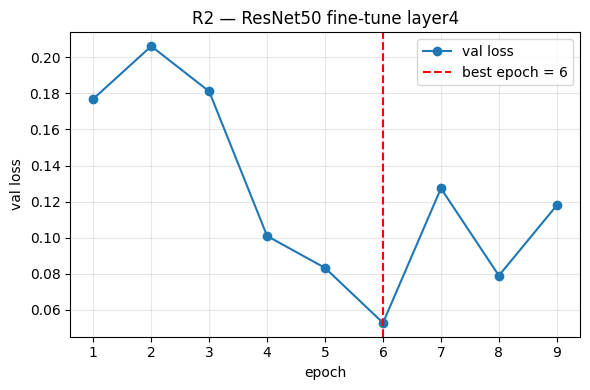

saved R2 -> /content/t20-brain-tumor-detection/results/metrics_pytorch.json


In [ ]:

seed_everything()

def build_resnet50_finetune():
    m = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
    for p in m.parameters():
        p.requires_grad = False
    for p in m.layer4.parameters():
        p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, 4)
    return Normalized(m)

model_r2 = build_resnet50_finetune()
r2 = run_training(model_r2, "R2", "ResNet50", "fine_tune_layer4", lr=1e-4, frozen=True)
r2["notes"] = "Adam lr=1e-4, batch=32, fine-tune layer4, BN in eval mode"
print({k: v for k, v in r2.items() if k != "_history"})


hist = r2["_history"]
best_ep = hist.index(min(hist)) + 1
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(hist) + 1), hist, marker="o", label="val loss")
plt.axvline(best_ep, color="red", linestyle="--", label=f"best epoch = {best_ep}")
plt.xlabel("epoch"); plt.ylabel("val loss"); plt.title("R2 — ResNet50 fine-tune layer4")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

save_run(r2)

In [ ]:
save_run(r2)

saved R2 -> /content/t20-brain-tumor-detection/results/metrics_pytorch.json


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 187MB/s]


R3 epoch  1 | val_loss=0.3946 | val_acc=0.8833 | 23.4s
R3 epoch  2 | val_loss=0.3610 | val_acc=0.8810 | 22.6s
R3 epoch  3 | val_loss=0.2889 | val_acc=0.9143 | 24.2s
R3 epoch  4 | val_loss=0.2607 | val_acc=0.9155 | 22.5s
R3 epoch  5 | val_loss=0.2484 | val_acc=0.9190 | 22.7s
R3 epoch  6 | val_loss=0.2393 | val_acc=0.9155 | 22.9s
R3 epoch  7 | val_loss=0.2340 | val_acc=0.9143 | 22.9s
R3 epoch  8 | val_loss=0.2343 | val_acc=0.9131 | 22.9s
R3 epoch  9 | val_loss=0.2259 | val_acc=0.9179 | 22.7s
R3 epoch 10 | val_loss=0.2139 | val_acc=0.9286 | 22.9s
R3 epoch 11 | val_loss=0.2085 | val_acc=0.9286 | 22.8s
R3 epoch 12 | val_loss=0.2148 | val_acc=0.9238 | 22.9s
R3 epoch 13 | val_loss=0.2192 | val_acc=0.9167 | 22.4s
R3 epoch 14 | val_loss=0.2183 | val_acc=0.9131 | 22.6s
R3: early stopping at epoch 14
{'framework': 'pytorch', 'architecture': 'EfficientNet-B0', 'strategy': 'frozen_backbone', 'run_id': 'R3', 'epochs_run': 14, 'seconds_per_epoch': 22.88, 'total_train_seconds': 365.98, 'peak_gpu_memor

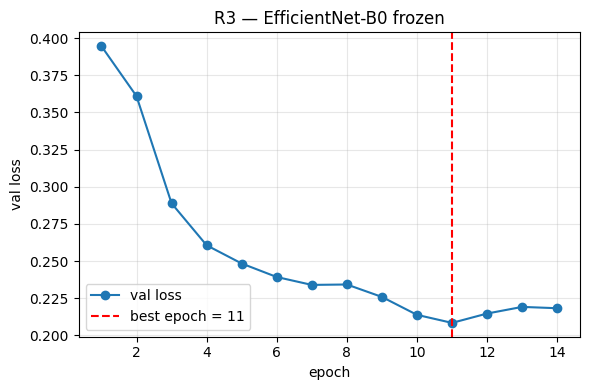

saved R3 -> /content/t20-brain-tumor-detection/results/metrics_pytorch.json


In [ ]:
from torchvision.models import EfficientNet_B0_Weights


del model_r1, model_r2
torch.cuda.empty_cache()

seed_everything()

def build_effnet_frozen():
    m = models.efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    for p in m.parameters():
        p.requires_grad = False
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 4)
    return Normalized(m)

model_r3 = build_effnet_frozen()
r3 = run_training(model_r3, "R3", "EfficientNet-B0", "frozen_backbone", lr=1e-3, frozen=True)
r3["notes"] = "Adam lr=1e-3, batch=32, frozen backbone, BN in eval mode, head dropout active"
print({k: v for k, v in r3.items() if k != "_history"})


hist = r3["_history"]
best_ep = hist.index(min(hist)) + 1
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(hist) + 1), hist, marker="o", label="val loss")
plt.axvline(best_ep, color="red", linestyle="--", label=f"best epoch = {best_ep}")
plt.xlabel("epoch"); plt.ylabel("val loss"); plt.title("R3 — EfficientNet-B0 frozen")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

save_run(r3)

In [ ]:
save_run(r3)

saved R3 -> /content/t20-brain-tumor-detection/results/metrics_pytorch.json


R4 epoch  1 | val_loss=0.4791 | val_acc=0.8560 | 22.9s
R4 epoch  2 | val_loss=0.3430 | val_acc=0.8964 | 23.0s
R4 epoch  3 | val_loss=0.2913 | val_acc=0.9036 | 23.1s
R4 epoch  4 | val_loss=0.2754 | val_acc=0.9071 | 23.4s
R4 epoch  5 | val_loss=0.2440 | val_acc=0.9250 | 24.0s
R4 epoch  6 | val_loss=0.2325 | val_acc=0.9143 | 23.3s
R4 epoch  7 | val_loss=0.2191 | val_acc=0.9202 | 23.1s
R4 epoch  8 | val_loss=0.2122 | val_acc=0.9274 | 23.1s
R4 epoch  9 | val_loss=0.2005 | val_acc=0.9298 | 23.3s
R4 epoch 10 | val_loss=0.2062 | val_acc=0.9274 | 23.2s
R4 epoch 11 | val_loss=0.2006 | val_acc=0.9345 | 23.2s
R4 epoch 12 | val_loss=0.2072 | val_acc=0.9238 | 23.3s
R4: early stopping at epoch 12
{'framework': 'pytorch', 'architecture': 'EfficientNet-B0', 'strategy': 'fine_tune_last_block', 'run_id': 'R4', 'epochs_run': 12, 'seconds_per_epoch': 23.25, 'total_train_seconds': 320.22, 'peak_gpu_memory_mb': 424, 'trainable_params': 417284, 'total_params': 4012672, 'saved_model_size_mb': 15.6, 'best_val_l

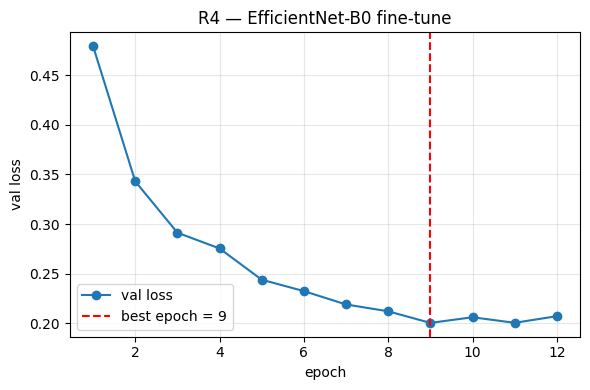

saved R4 -> /content/t20-brain-tumor-detection/results/metrics_pytorch.json


In [ ]:

del model_r3
torch.cuda.empty_cache()

seed_everything()

def build_effnet_finetune():
    m = models.efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    for p in m.parameters():
        p.requires_grad = False
    for p in m.features[-1].parameters():
        p.requires_grad = True
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 4)
    return Normalized(m)

model_r4 = build_effnet_finetune()
r4 = run_training(model_r4, "R4", "EfficientNet-B0", "fine_tune_last_block", lr=1e-4, frozen=True)
r4["notes"] = "Adam lr=1e-4, batch=32, fine-tune features[-1], BN in eval mode, head dropout active"
print({k: v for k, v in r4.items() if k != "_history"})


hist = r4["_history"]
best_ep = hist.index(min(hist)) + 1
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(hist) + 1), hist, marker="o", label="val loss")
plt.axvline(best_ep, color="red", linestyle="--", label=f"best epoch = {best_ep}")
plt.xlabel("epoch"); plt.ylabel("val loss"); plt.title("R4 — EfficientNet-B0 fine-tune")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

save_run(r4)

In [ ]:
seed_everything()

model_final = build_resnet50_finetune()
r2b = run_training(model_final, "R2", "ResNet50", "fine_tune_layer4", lr=1e-4, frozen=True)
r2b["notes"] = "Adam lr=1e-4, batch=32, fine-tune layer4, BN in eval mode (final model, retrained with same seed)"
print({k: v for k, v in r2b.items() if k != "_history"})


torch.save(model_final.state_dict(), "/content/model_r2_best_state.pt")
print("saved best weights")

save_run(r2b)

R2 epoch  1 | val_loss=0.2718 | val_acc=0.9131 | 29.1s
R2 epoch  2 | val_loss=0.1523 | val_acc=0.9440 | 25.5s
R2 epoch  3 | val_loss=0.1361 | val_acc=0.9512 | 25.3s
R2 epoch  4 | val_loss=0.1144 | val_acc=0.9571 | 26.0s
R2 epoch  5 | val_loss=0.1283 | val_acc=0.9560 | 25.6s
R2 epoch  6 | val_loss=0.0846 | val_acc=0.9726 | 25.9s
R2 epoch  7 | val_loss=0.0689 | val_acc=0.9810 | 25.8s
R2 epoch  8 | val_loss=0.0513 | val_acc=0.9821 | 25.7s
R2 epoch  9 | val_loss=0.0552 | val_acc=0.9798 | 25.6s
R2 epoch 10 | val_loss=0.0861 | val_acc=0.9667 | 25.7s
R2 epoch 11 | val_loss=0.0542 | val_acc=0.9810 | 25.6s
R2: early stopping at epoch 11
{'framework': 'pytorch', 'architecture': 'ResNet50', 'strategy': 'fine_tune_layer4', 'run_id': 'R2', 'epochs_run': 11, 'seconds_per_epoch': 25.99, 'total_train_seconds': 330.64, 'peak_gpu_memory_mb': 765, 'trainable_params': 14972932, 'total_params': 23516228, 'saved_model_size_mb': 90.01, 'best_val_loss': 0.0513, 'best_val_acc': 0.9821, 'notes': 'Adam lr=1e-4, 

test samples: 1600
=== R2 final — TEST ===
Accuracy: 0.9400
              precision    recall  f1-score   support

      glioma     0.9847    0.8025    0.8843       400
  meningioma     0.8846    0.9775    0.9287       400
     notumor     0.9217    1.0000    0.9592       400
   pituitary     0.9849    0.9800    0.9825       400

    accuracy                         0.9400      1600
   macro avg     0.9440    0.9400    0.9387      1600
weighted avg     0.9440    0.9400    0.9387      1600



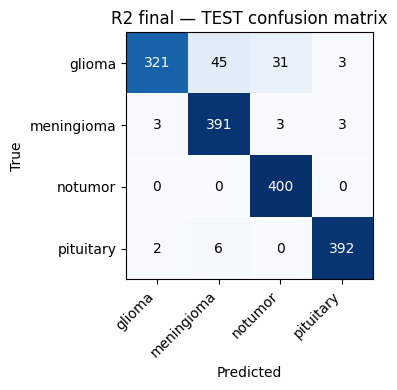

saved final_model to JSON


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


def evaluate_predictions(y_true, y_pred, classes=CLASSES, title=""):
    acc = accuracy_score(y_true, y_pred)
    rep = classification_report(y_true, y_pred, target_names=classes, digits=4,
                                output_dict=True, zero_division=0)
    print(f"=== {title} ===")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, target_names=classes,
                                digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(f"{title} confusion matrix")
    fig.tight_layout()
    plt.show()
    return {"accuracy": acc,
            "macro_precision": rep["macro avg"]["precision"],
            "macro_recall": rep["macro avg"]["recall"],
            "macro_f1": rep["macro avg"]["f1-score"],
            "per_class": {c: rep[c] for c in classes},
            "confusion_matrix": cm.tolist()}

@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        out = model(x.to(device))
        ps.append(out.argmax(1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)


y_test, p_test = predict_all(model_final, test_loader)
print("test samples:", len(y_test))
test_res = evaluate_predictions(y_test, p_test, title="R2 final — TEST")


with open(RES_PATH) as f:
    data = json.load(f)
data["final_model"] = {
    "selected_run": "R2",
    "test_accuracy": round(test_res["accuracy"], 4),
    "macro_precision": round(test_res["macro_precision"], 4),
    "macro_recall": round(test_res["macro_recall"], 4),
    "macro_f1": round(test_res["macro_f1"], 4),
    "per_class": {c: {k: round(float(v), 4) for k, v in d.items()} for c, d in test_res["per_class"].items()},
    "confusion_matrix": test_res["confusion_matrix"],
    "gradcam_done": False,
    "model_file_mb": None,
}
with open(RES_PATH, "w") as f:
    json.dump(data, f, indent=2)
print("saved final_model to JSON")

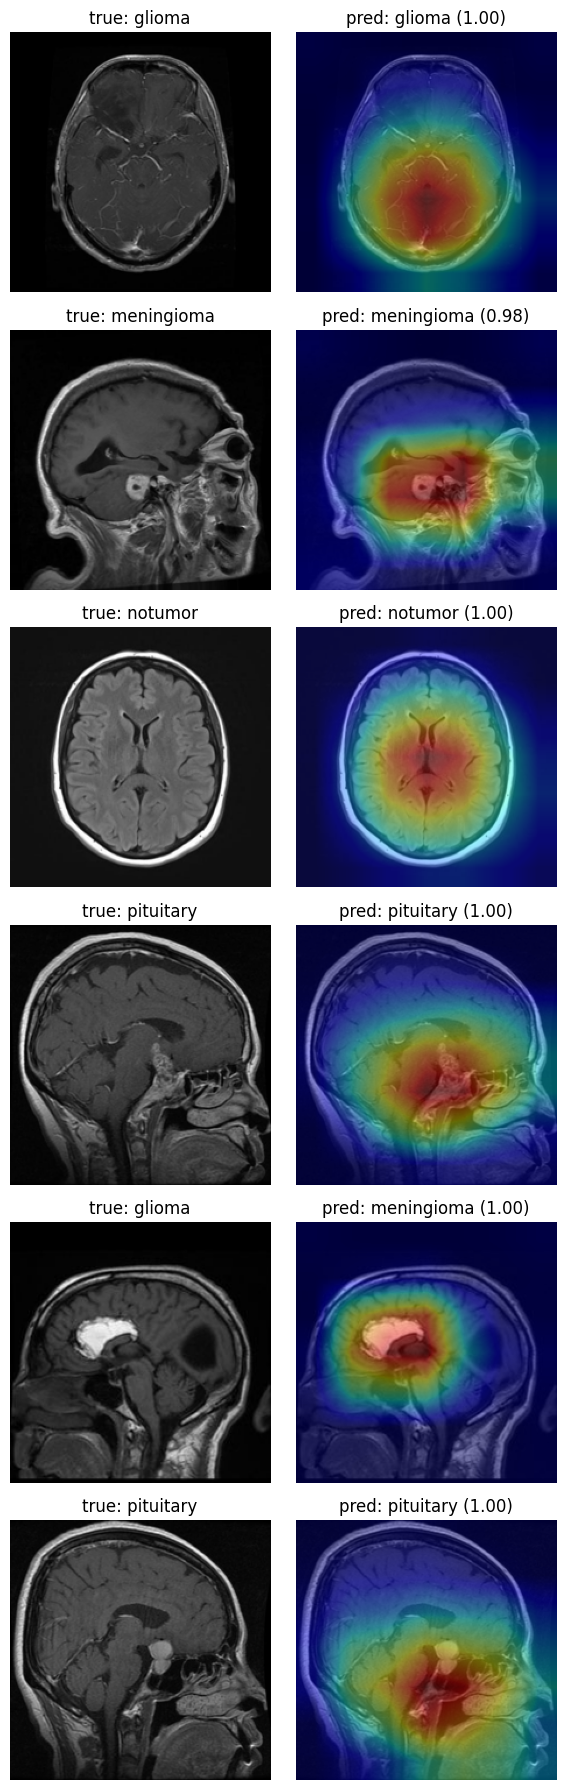

misclassified in test: 96
/content/t20-brain-tumor-detection/data/Testing/glioma/Te-gl_101.jpg | true = glioma | pred = meningioma
/content/t20-brain-tumor-detection/data/Testing/glioma/Te-gl_102.jpg | true = glioma | pred = notumor
/content/t20-brain-tumor-detection/data/Testing/glioma/Te-gl_103.jpg | true = glioma | pred = notumor
/content/t20-brain-tumor-detection/data/Testing/glioma/Te-gl_106.jpg | true = glioma | pred = meningioma
/content/t20-brain-tumor-detection/data/Testing/glioma/Te-gl_109.jpg | true = glioma | pred = meningioma


In [ ]:

GRADCAM_TEST_PATHS = [
    "data/Testing/glioma/Te-gl_100.jpg",
    "data/Testing/meningioma/Te-aug-me_100.jpg",
    "data/Testing/notumor/Te-no_100.jpg",
    "data/Testing/pituitary/Te-pi_100.jpg",
    "data/Testing/glioma/Te-gl_109.jpg",
    "data/Testing/pituitary/Te-pi_109.jpg",
]

def gradcam(model, x, layer, cls=None):
    store = {}
    def fwd(m, i, o):
        store["a"] = o
    h = layer.register_forward_hook(fwd)
    out = model(x)
    h.remove()
    if cls is None:
        cls = out.argmax(1).item()
    g = torch.autograd.grad(out[0, cls], store["a"])[0]
    w = g.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    probs = torch.softmax(out, 1)[0].detach().cpu().numpy()
    return cam.detach().cpu().numpy(), cls, probs

import torch.nn.functional as F
model_final.eval()
target_layer = model_final.base.layer4[-1]

fig, axes = plt.subplots(len(GRADCAM_TEST_PATHS), 2, figsize=(6, 3 * len(GRADCAM_TEST_PATHS)))
for r, p in enumerate(GRADCAM_TEST_PATHS):
    img = Image.open(p).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    x = eval_tf(img).unsqueeze(0).to(device)
    cam, pred, probs = gradcam(model_final, x, target_layer)
    true = p.split("/")[-2]
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"true: {true}")
    axes[r, 1].imshow(img)
    axes[r, 1].imshow(cam, cmap="jet", alpha=0.4)
    axes[r, 1].set_title(f"pred: {CLASSES[pred]} ({probs[pred]:.2f})")
    axes[r, 0].axis("off"); axes[r, 1].axis("off")
plt.tight_layout(); plt.show()


wrong = np.where(y_test != p_test)[0]
print("misclassified in test:", len(wrong))
for i in wrong[:5]:
    print(test_df.path.iloc[i], "| true =", CLASSES[y_test[i]], "| pred =", CLASSES[p_test[i]])

In [ ]:

mis_path = test_df.path.iloc[wrong[0]].replace("/content/t20-brain-tumor-detection/", "")
print("7th image:", mis_path, "| true =", CLASSES[y_test[wrong[0]]], "| pred =", CLASSES[p_test[wrong[0]]])

GRADCAM_TEST_PATHS.append(mis_path)
print("total images:", len(GRADCAM_TEST_PATHS))


GRADCAM_TEST_PATHS = list(dict.fromkeys(GRADCAM_TEST_PATHS))
print("total images:", len(GRADCAM_TEST_PATHS))
for p in GRADCAM_TEST_PATHS:
    print(" -", p)

7th image: data/Testing/glioma/Te-gl_101.jpg | true = glioma | pred = meningioma
total images: 11
total images: 7
 - data/Testing/glioma/Te-gl_100.jpg
 - data/Testing/meningioma/Te-aug-me_100.jpg
 - data/Testing/notumor/Te-no_100.jpg
 - data/Testing/pituitary/Te-pi_100.jpg
 - data/Testing/glioma/Te-gl_109.jpg
 - data/Testing/pituitary/Te-pi_109.jpg
 - data/Testing/glioma/Te-gl_101.jpg


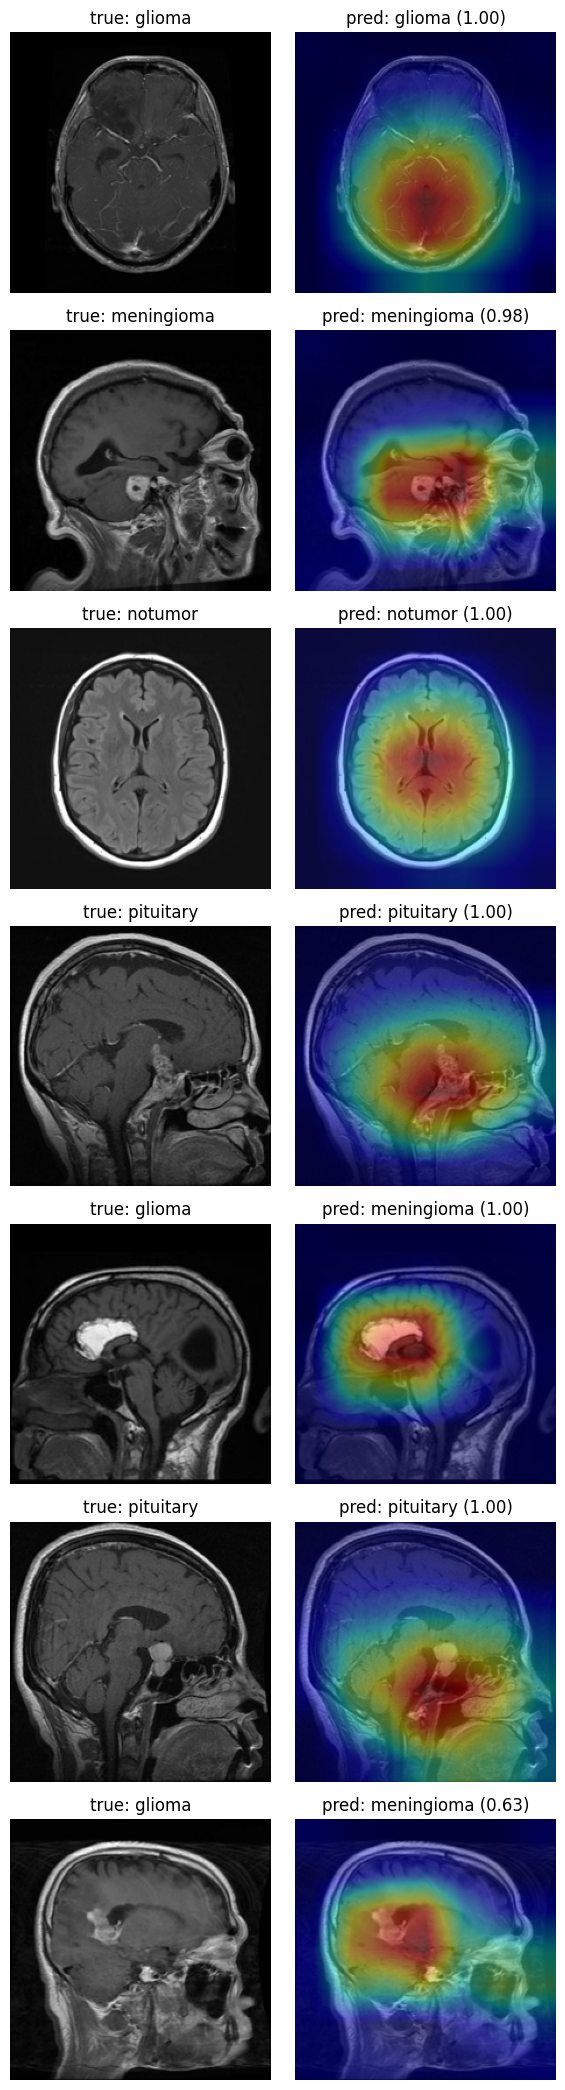

In [ ]:
fig, axes = plt.subplots(len(GRADCAM_TEST_PATHS), 2, figsize=(6, 3 * len(GRADCAM_TEST_PATHS)))
target_layer = model_final.base.layer4[-1]

for r, p in enumerate(GRADCAM_TEST_PATHS):
    img = Image.open(p).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    x = eval_tf(img).unsqueeze(0).to(device)
    cam, pred, probs = gradcam(model_final, x, target_layer)
    true = p.split("/")[-2]

    axes[r, 0].imshow(img)
    axes[r, 0].set_title(f"true: {true}")
    axes[r, 1].imshow(img)
    axes[r, 1].imshow(cam, cmap="jet", alpha=0.4)
    axes[r, 1].set_title(f"pred: {CLASSES[pred]} ({probs[pred]:.2f})")
    axes[r, 0].axis("off"); axes[r, 1].axis("off")

plt.tight_layout()
plt.show()

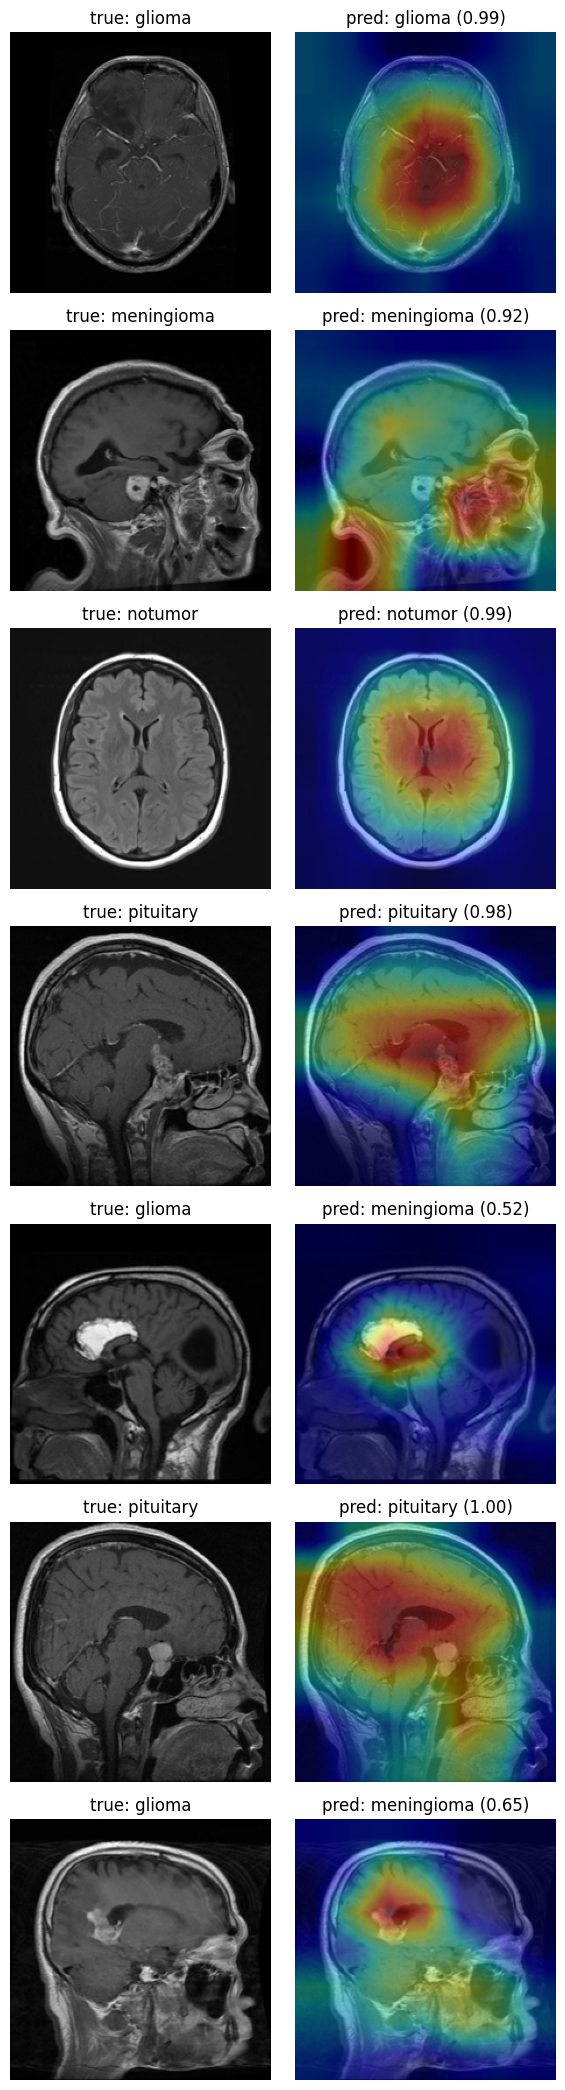

In [ ]:
target_layer_eff = model_r4.base.features[-1]
model_r4.eval()

fig, axes = plt.subplots(len(GRADCAM_TEST_PATHS), 2, figsize=(6, 3 * len(GRADCAM_TEST_PATHS)))
for r, p in enumerate(GRADCAM_TEST_PATHS):
    img = Image.open(p).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    x = eval_tf(img).unsqueeze(0).to(device)
    cam, pred, probs = gradcam(model_r4, x, target_layer_eff)
    true = p.split("/")[-2]
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"true: {true}")
    axes[r, 1].imshow(img); axes[r, 1].imshow(cam, cmap="jet", alpha=0.4)
    axes[r, 1].set_title(f"pred: {CLASSES[pred]} ({probs[pred]:.2f})")
    axes[r, 0].axis("off"); axes[r, 1].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
import os
model_cpu = model_final.to("cpu").eval()
traced = torch.jit.trace(model_cpu, torch.rand(1, 3, IMAGE_SIZE, IMAGE_SIZE))
traced.save("model/model_T20.pt")

size_mb = os.path.getsize("model/model_T20.pt") / 1024**2
print(f"size: {size_mb:.2f} MB")


loaded = torch.jit.load("model/model_T20.pt", map_location="cpu").eval()
xb, _ = next(iter(test_loader))
with torch.no_grad():
    a = model_cpu(xb[:8]).argmax(1)
    b = loaded(xb[:8]).argmax(1)
print("same predictions:", bool((a == b).all()))

size: 90.27 MB
same predictions: True


In [ ]:
with open(RES_PATH) as f:
    data = json.load(f)
data["final_model"]["gradcam_done"] = True
data["final_model"]["model_file_mb"] = round(os.path.getsize("model/model_T20.pt") / 1024**2, 2)
with open(RES_PATH, "w") as f:
    json.dump(data, f, indent=2)
print(json.dumps(data["final_model"]["model_file_mb"]), data["final_model"]["gradcam_done"])



90.27 True


In [ ]:
import torch
   m = torch.jit.load("model/model_T20.pt", map_location="cpu").eval()
   print(m(torch.rand(1, 3, 224, 224)).shape)

torch.Size([1, 4])


In [ ]:
!mv /content/pytorch_T20.ipynb /content/t20-brain-tumor-detection/notebooks/pytorch_T20.ipynb
!ls -lh /content/t20-brain-tumor-detection/notebooks/

total 2.1M
-rw-r--r-- 1 root root 2.0M Oct 25 01:45 pytorch_T20.ipynb
-rw-r--r-- 1 root root 1.4K Oct 25 00:25 README_split.md
-rw-r--r-- 1 root root 6.8K Oct 25 00:25 shared_cells.py


In [ ]:
%cd /content/t20-brain-tumor-detection
!git config user.name "Moatasem"
!git config user.email ""moatasemmohamed558@gmail.com
!git status --short

/content/t20-brain-tumor-detection
 M model/model_T20.pt
 M results/metrics_pytorch.json
?? notebooks/pytorch_T20.ipynb


In [ ]:
!git add notebooks/pytorch_T20.ipynb results/metrics_pytorch.json model/model_T20.pt
!git commit -m "pytorch: R1-R4, final eval, GradCAM, final model"
!git push

[main 029f3ae] pytorch: R1-R4, final eval, GradCAM, final model
 3 files changed, 1172 insertions(+), 20 deletions(-)
 create mode 100644 notebooks/pytorch_T20.ipynb
Enumerating objects: 14, done.
Counting objects: 100% (14/14), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (8/8), 85.18 MiB | 9.21 MiB/s, done.
Total 8 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
remote: warning: See https://gh.io/lfs for more information.
remote: warning: File model/model_T20.pt is 90.27 MB; this is larger than GitHub's recommended maximum file size of 50.00 MB
remote: warning: GH001: Large files detected. You may want to try Git Large File Storage - https://git-lfs.github.com.
To https://github.com/sayfeldinn/t20-brain-tumor-detection.git
   3dd8855..029f3ae  main -> main


In [ ]:
import json
path = "/content/t20-brain-tumor-detection/notebooks/pytorch_T20.ipynb"
try:
    nb = json.load(open(path, encoding="utf-8"))
    print("valid JSON, cells:", len(nb["cells"]))
except Exception as e:
    print("INVALID:", e)
!head -c 150 {path}
!tail -c 150 {path}

INVALID: Unterminated string starting at: line 1054 column 26 (char 1418054)
{
  "nbformat": 4,
  "nbformat_minor": 0,
  "metadata": {
    "colab": {
      "provenance": [],
      "gpuType": "T4"
    },
    "kernelspec": {
    mRnx3wHgRgMfR40ctPYqeSiYklm6/k9TcKMAMF5gvUuPTRcNut6eqHO1kQlU5Ri/dwG1rmc6mwsClycyu2xFtpJm2zKZTJvMpi9WcxemCqq049AceNg9sDhvJOHJCgdV1xbSdUE+FpVmeL5kspOQ0h

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!find /content/drive/MyDrive -name "pytorch_T20.ipynb" 2>/dev/null

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/pytorch_T20.ipynb
